# **Project Name**    - Zomato Restaurant Clustering



##### **Project Type**    - Unsupervised/ Clustering
##### **Contribution**    - Individual

# **Project Summary -**

This project focuses on analysing Zomato restaurant information and grouping restaurants into meaningful clusters using unsupervised machine learning techniques.

Two datasets are used in this project. The restaurant metadata dataset contains 105 restaurants and 6 variables: restaurant name, link, cost, collections, cuisines and timings. The restaurant reviews dataset contains 10,000 review records and 7 variables: restaurant, reviewer, review, rating, metadata, time and pictures.

The metadata and review datasets are combined at restaurant level. Review-level information is aggregated to create restaurant-level features such as average rating, number of reviews, picture activity and review text. Cost is converted into a numerical variable, while cuisine and collection information is represented using TF-IDF.

The project begins with data understanding, data cleaning and exploratory data analysis. Univariate, bivariate and multivariate visualizations are used to understand restaurant cost, ratings, cuisine categories, review activity, picture activity and relationships among restaurant characteristics.

For clustering, restaurant-level text information is transformed using TF-IDF. Numerical features such as average rating, review count, cost and picture activity are standardized and combined with the text representation. Truncated SVD is then used to reduce the high-dimensional feature matrix.

K-Means, Agglomerative Clustering and Gaussian Mixture clustering are implemented and compared using clustering-specific evaluation metrics. The optimal number of clusters for K-Means is selected using the Elbow Method and Silhouette Score. The final clusters are profiled using restaurant characteristics so that the machine-learning output can be interpreted from a business perspective.

The resulting restaurant segments can help a food-discovery platform understand groups such as highly rated premium restaurants, affordable popular restaurants, and restaurants with different cuisine or review profiles. These segments can support recommendation systems, restaurant discovery, targeted promotions and business planning.

# **GitHub Link -**

https://github.com/SamruddhiChandurkar/Zomato-Restaurant-Clustering-ML

# **Problem Statement**


Zomato contains restaurants with different price ranges, cuisines, ratings, customer-review patterns, collections and operating schedules. Treating every restaurant as an independent record makes it difficult to discover broader restaurant segments.

The objective of this project is to use unsupervised machine learning to identify natural groups of similar restaurants. These clusters can be used for restaurant recommendation, customer segmentation, promotional campaigns and catalogue analysis.

Key Questions
1. What are the major characteristics of the restaurants in the dataset?
2. Which cuisines and cost ranges are most common?
1. How are restaurant ratings related to review activity and cost?
2. Can restaurants be grouped into meaningful clusters without a predefined target variable?
1. Which clustering algorithm and number of clusters provide the most useful segmentation?
2. How can the discovered restaurant clusters create business value?











# **General Guidelines** : -  

1.   Well-structured, formatted, and commented code is required.
2.   Exception Handling, Production Grade Code & Deployment Ready Code will be a plus. Those students will be awarded some additional credits.
     
     The additional credits will have advantages over other students during Star Student selection.
       
             [ Note: - Deployment Ready Code is defined as, the whole .ipynb notebook should be executable in one go
                       without a single error logged. ]

3.   Each and every logic should have proper comments.
4. You may add as many number of charts you want. Make Sure for each and every chart the following format should be answered.
        

```
# Chart visualization code
```
            

*   Why did you pick the specific chart?
*   What is/are the insight(s) found from the chart?
* Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

5. You have to create at least 15 logical & meaningful charts having important insights.


[ Hints : - Do the Vizualization in  a structured way while following "UBM" Rule.

U - Univariate Analysis,

B - Bivariate Analysis (Numerical - Categorical, Numerical - Numerical, Categorical - Categorical)

M - Multivariate Analysis
 ]





6. You may add more ml algorithms for model creation. Make sure for each and every algorithm, the following format should be answered.


*   Explain the ML Model used and it's performance using Evaluation metric Score Chart.


*   Cross- Validation & Hyperparameter Tuning

*   Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

*   Explain each evaluation metric's indication towards business and the business impact pf the ML model used.




















# ***Let's Begin !***

## ***1. Know Your Data***

### Import Libraries

In [1]:
# Import Libraries
import os
import re
import warnings
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from scipy import stats
from scipy.sparse import hstack, csr_matrix

from sklearn.preprocessing import StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import TruncatedSVD
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (
    silhouette_score,
    calinski_harabasz_score,
    davies_bouldin_score
)

warnings.filterwarnings('ignore')
sns.set_style('darkgrid')
plt.rcParams['figure.figsize'] = (10, 6)

### Dataset Loading

In [2]:
# Load Dataset
metadata_path = '/content/Zomato Restaurant names and Metadata.csv'
reviews_path = '/content/Zomato Restaurant reviews.csv'

# If the files are not already available in Colab, upload them.
if not (os.path.exists(metadata_path) and os.path.exists(reviews_path)):
    try:
        from google.colab import files
        uploaded = files.upload()
        uploaded_names = list(uploaded.keys())

        for name in uploaded_names:
            if 'Metadata' in name:
                metadata_path = name
            elif 'reviews' in name.lower():
                reviews_path = name
    except Exception:
        pass

metadata = pd.read_csv(metadata_path)
reviews = pd.read_csv(reviews_path)

### Dataset First View

In [3]:
# Dataset First Look
metadata.head()
reviews.head()

,Restaurant,Reviewer,Review,Rating,Metadata,Time,Pictures
0,Beyond Flavours,Rusha Chakraborty,"The ambience was good, food was quite good . h...",5,"1 Review , 2 Followers",5/25/2019 15:54,0
1,Beyond Flavours,Anusha Tirumalaneedi,Ambience is too good for a pleasant evening. S...,5,"3 Reviews , 2 Followers",5/25/2019 14:20,0
2,Beyond Flavours,Ashok Shekhawat,A must try.. great food great ambience. Thnx f...,5,"2 Reviews , 3 Followers",5/24/2019 22:54,0
3,Beyond Flavours,Swapnil Sarkar,Soumen das and Arun was a great guy. Only beca...,5,"1 Review , 1 Follower",5/24/2019 22:11,0
4,Beyond Flavours,Dileep,Food is good.we ordered Kodi drumsticks and ba...,5,"3 Reviews , 2 Followers",5/24/2019 21:37,0


### Dataset Rows & Columns count

In [4]:
# Dataset Rows & Columns count
print("Restaurant metadata shape:", metadata.shape)
print("Restaurant reviews shape:", reviews.shape)

Restaurant metadata shape: (105, 6)
Restaurant reviews shape: (10000, 7)


### Dataset Information

In [5]:
# Dataset Info
print("Restaurant Metadata Information:")
metadata.info()

print("\nRestaurant Reviews Information:")
reviews.info()

Restaurant Metadata Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 105 entries, 0 to 104
Data columns (total 6 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   Name         105 non-null    object
 1   Links        105 non-null    object
 2   Cost         105 non-null    object
 3   Collections  51 non-null     object
 4   Cuisines     105 non-null    object
 5   Timings      104 non-null    object
dtypes: object(6)
memory usage: 5.1+ KB

Restaurant Reviews Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Restaurant  10000 non-null  object
 1   Reviewer    9962 non-null   object
 2   Review      9955 non-null   object
 3   Rating      9962 non-null   object
 4   Metadata    9962 non-null   object
 5   Time        9962 non-null   object
 6   Pictures    10000 non-null  in

#### Duplicate Values

In [6]:
# Dataset Duplicate Value Count
print("Duplicate metadata rows:", metadata.duplicated().sum())
print("Duplicate review rows:", reviews.duplicated().sum())

Duplicate metadata rows: 0
Duplicate review rows: 36


#### Missing Values/Null Values

In [7]:
# Missing Values/Null Values Count
print("Metadata missing values:")
print(metadata.isnull().sum())

print("\nReviews missing values:")
print(reviews.isnull().sum())

Metadata missing values:
Name            0
Links           0
Cost            0
Collections    54
Cuisines        0
Timings         1
dtype: int64

Reviews missing values:
Restaurant     0
Reviewer      38
Review        45
Rating        38
Metadata      38
Time          38
Pictures       0
dtype: int64


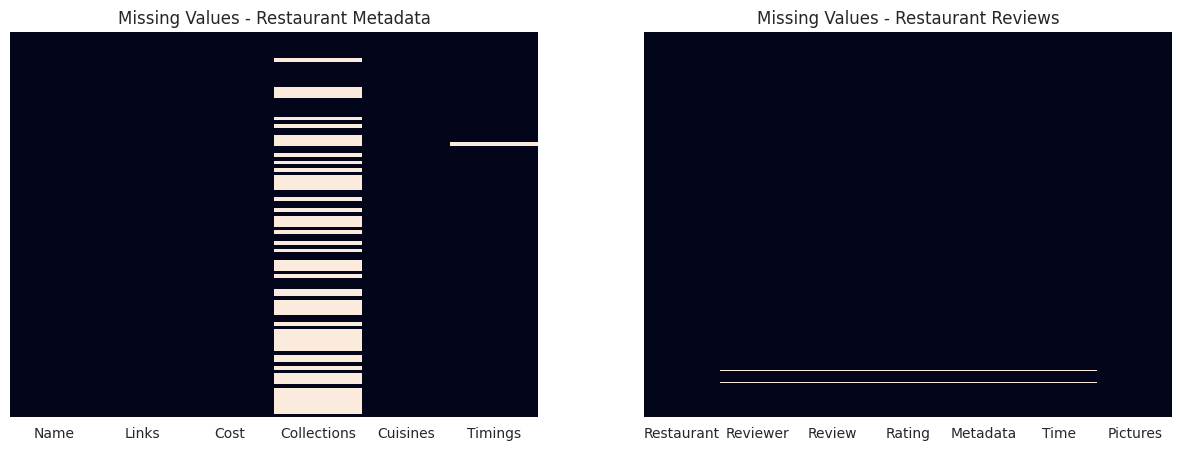

In [8]:
# Visualizing the missing values
fig, ax = plt.subplots(1, 2, figsize=(15, 5))

sns.heatmap(metadata.isnull(), cbar=False, yticklabels=False, ax=ax[0])
ax[0].set_title('Missing Values - Restaurant Metadata')

sns.heatmap(reviews.isnull(), cbar=False, yticklabels=False, ax=ax[1])
ax[1].set_title('Missing Values - Restaurant Reviews')

plt.show()

### What did you know about your dataset?

The restaurant metadata file contains **105 restaurant records and 6 columns**, while the review file contains **10,000 review records and 7 columns**.

The metadata includes restaurant-level information such as cost, collections, cuisines and timings. The review dataset provides customer-level review information such as rating, review text, metadata, time and pictures.

The review data covers **100 unique restaurants**, all of which are present in the metadata dataset. Therefore, the review information can be aggregated and merged into the restaurant metadata to create a single restaurant-level clustering dataset.

There are missing values in several fields. Missing collections are present in the metadata, while review-related fields such as reviewer, review, rating, metadata and time contain some missing observations. These are handled during preprocessing rather than dropping large portions of the data.

## ***2. Understanding Your Variables***

In [9]:
# Dataset columns
print("Metadata columns:")
print(metadata.columns.tolist())

print("\nReview columns:")
print(reviews.columns.tolist())

Metadata columns:
['Name', 'Links', 'Cost', 'Collections', 'Cuisines', 'Timings']

Review columns:
['Restaurant', 'Reviewer', 'Review', 'Rating', 'Metadata', 'Time', 'Pictures']


In [10]:
# Dataset Describe
print("Metadata description:")
display(metadata.describe(include='all').T)

print("Reviews description:")
display(reviews.describe(include='all').T)

Metadata description:


,count,unique,top,freq
Name,105,105,Beyond Flavours,1
Links,105,105,https://www.zomato.com/hyderabad/beyond-flavou...,1
Cost,105,29,500,13
Collections,51,42,Food Hygiene Rated Restaurants in Hyderabad,4
Cuisines,105,92,"North Indian, Chinese",4
Timings,104,77,11 AM to 11 PM,6


Reviews description:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Restaurant,10000,100,Beyond Flavours,100,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Reviewer,9962,7446,Parijat Ray,13,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Review,9955,9364,good,237,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Rating,9962,10,5,3832,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Metadata,9962,2477,1 Review,919,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Time,9962,9782,7/29/2018 20:34,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Pictures,10000.0,NaN,NaN,NaN,0.7486,2.570381,0.0,0.0,0.0,0.0,64.0


### Variables Description

#### Restaurant Metadata

* **Name** - Name of the restaurant.
* **Links** - Zomato link associated with the restaurant.
* **Cost** - Approximate cost information for the restaurant.
* **Collections** - Zomato collection/category information associated with the restaurant.
* **Cuisines** - Cuisine types offered by the restaurant.
* **Timings** - Restaurant operating hours.

#### Restaurant Reviews

* **Restaurant** - Restaurant name associated with the review.
* **Reviewer** - Customer/reviewer name.
* **Review** - Customer review text.
* **Rating** - Rating given by the customer.
* **Metadata** - Additional review-related metadata.
* **Time** - Date and time of the review.
* **Pictures** - Number of pictures associated with the review.

### Check Unique Values for each variable.

In [11]:
# Check Unique Values for each variable.
for col in metadata.columns:
    print(f"Metadata - {col}: {metadata[col].nunique()} unique values")

print("\nReview-level unique values:")
for col in reviews.columns:
    print(f"Reviews - {col}: {reviews[col].nunique()} unique values")

Metadata - Name: 105 unique values
Metadata - Links: 105 unique values
Metadata - Cost: 29 unique values
Metadata - Collections: 42 unique values
Metadata - Cuisines: 92 unique values
Metadata - Timings: 77 unique values

Review-level unique values:
Reviews - Restaurant: 100 unique values
Reviews - Reviewer: 7446 unique values
Reviews - Review: 9364 unique values
Reviews - Rating: 10 unique values
Reviews - Metadata: 2477 unique values
Reviews - Time: 9782 unique values
Reviews - Pictures: 36 unique values


## 3. ***Data Wrangling***

### Data Wrangling Code

In [12]:
# Write your code to make your dataset analysis ready.
# Create copies of the original data
meta = metadata.copy()
rev = reviews.copy()

# Standardize column names
meta.columns = meta.columns.str.strip()
rev.columns = rev.columns.str.strip()

# Clean restaurant names for reliable merging
meta['Name'] = meta['Name'].astype(str).str.strip()
rev['Restaurant'] = rev['Restaurant'].astype(str).str.strip()

# Clean cost
meta['Cost_num'] = (
    meta['Cost'].astype(str)
    .str.replace(',', '', regex=False)
    .str.extract(r'(\d+\.?\d*)')[0]
    .astype(float)
)

# Clean ratings
rev['Rating_num'] = pd.to_numeric(
    rev['Rating'].astype(str).str.extract(r'(\d+\.?\d*)')[0],
    errors='coerce'
)

# Convert review time
rev['Time'] = pd.to_datetime(rev['Time'], errors='coerce')

# Clean review text
rev['Review_clean'] = rev['Review'].fillna('').astype(str).str.strip()

# Clean pictures
rev['Pictures_num'] = pd.to_numeric(rev['Pictures'], errors='coerce').fillna(0)

# Clean collections/cuisines
meta['Collections'] = meta['Collections'].fillna('Unknown').astype(str)
meta['Cuisines'] = meta['Cuisines'].fillna('Unknown').astype(str)
meta['Timings'] = meta['Timings'].fillna('Unknown').astype(str)

# Aggregate reviews at restaurant level
review_agg = rev.groupby('Restaurant').agg(
    Avg_Rating=('Rating_num', 'mean'),
    Rating_Count=('Rating_num', 'count'),
    Review_Count=('Review_clean', 'count'),
    Picture_Count=('Pictures_num', 'sum'),
    Avg_Pictures_Per_Review=('Pictures_num', 'mean')
).reset_index()

# Concatenate all review text by restaurant
review_text = (
    rev.groupby('Restaurant')['Review_clean']
    .apply(lambda x: ' '.join(x))
    .reset_index(name='Review_Text')
)

review_features = review_agg.merge(review_text, on='Restaurant', how='left')

# Merge restaurant metadata with review-level aggregates
df = meta.merge(
    review_features,
    left_on='Name',
    right_on='Restaurant',
    how='left'
)

# Fill restaurants without reviews
for col in ['Avg_Rating', 'Rating_Count', 'Review_Count', 'Picture_Count', 'Avg_Pictures_Per_Review']:
    df[col] = df[col].fillna(0)

df['Review_Text'] = df['Review_Text'].fillna('')

# Remove duplicate merge helper column
if 'Restaurant' in df.columns:
    df.drop(columns=['Restaurant'], inplace=True)

df.head()

#dataset after merging
print("Restaurant-level dataset shape:", df.shape)
df.head()

Restaurant-level dataset shape: (105, 13)


,Name,Links,Cost,Collections,Cuisines,Timings,Cost_num,Avg_Rating,Rating_Count,Review_Count,Picture_Count,Avg_Pictures_Per_Review,Review_Text
0,Beyond Flavours,https://www.zomato.com/hyderabad/beyond-flavou...,800,"Food Hygiene Rated Restaurants in Hyderabad, C...","Chinese, Continental, Kebab, European, South I...","12noon to 3:30pm, 6:30pm to 11:30pm (Mon-Sun)",800.0,4.28,100.0,100.0,39.0,0.39,"The ambience was good, food was quite good . h..."
1,Paradise,https://www.zomato.com/hyderabad/paradise-gach...,800,Hyderabad's Hottest,"Biryani, North Indian, Chinese",11 AM to 11 PM,800.0,4.70,100.0,100.0,2.0,0.02,Paradise Biryani is really good service also g...
2,Flechazo,https://www.zomato.com/hyderabad/flechazo-gach...,"1,300","Great Buffets, Hyderabad's Hottest","Asian, Mediterranean, North Indian, Desserts","11:30 AM to 4:30 PM, 6:30 PM to 11 PM",1300.0,4.66,100.0,100.0,55.0,0.55,We were 4 people who visited this place on Thu...
3,Shah Ghouse Hotel & Restaurant,https://www.zomato.com/hyderabad/shah-ghouse-h...,800,Late Night Restaurants,"Biryani, North Indian, Chinese, Seafood, Bever...",12 Noon to 2 AM,800.0,3.21,100.0,100.0,30.0,0.30,"Haleem, the best place to try out.\nAvaialble ..."
4,Over The Moon Brew Company,https://www.zomato.com/hyderabad/over-the-moon...,"1,200","Best Bars & Pubs, Food Hygiene Rated Restauran...","Asian, Continental, North Indian, Chinese, Med...","12noon to 11pm (Mon, Tue, Wed, Thu, Sun), 12no...",1200.0,4.34,100.0,100.0,44.0,0.44,"Great ambience, met an excellent man - Sarbesh..."


### What all manipulations have you done and insights you found?

The following transformations were performed:

1. Both datasets were copied to preserve the original data.
2. Restaurant names were standardized before merging.
3. The `Cost` column was converted from text into a numerical cost feature.
4. Review ratings were converted into numerical values.
5. Review timestamps were converted into datetime format.
6. Missing review text was replaced with an empty string.
7. Review-level information was aggregated by restaurant to obtain average rating, rating count, review count and picture activity.
8. All review text for each restaurant was combined into a single restaurant-level text field.
9. The metadata and aggregated review features were merged using restaurant name.
10. Restaurants without review records were retained and their review-based numerical features were set to zero.

This creates one observation per restaurant, which is the appropriate level for restaurant clustering.


## ***4. Data Vizualization, Storytelling & Experimenting with charts : Understand the relationships between variables***

#### Chart - 1 - Restaurant Cost Distribution

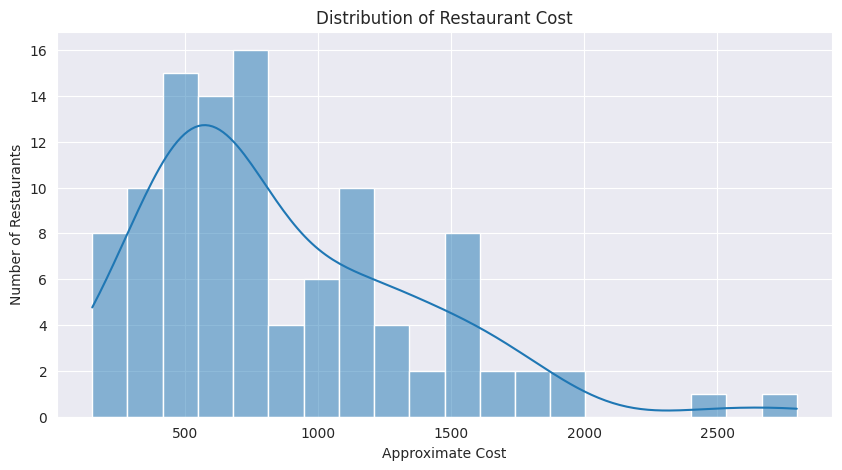

In [13]:
# Chart - 1 visualization code
plt.figure(figsize=(10, 5))
sns.histplot(df['Cost_num'], bins=20, kde=True)
plt.title('Distribution of Restaurant Cost')
plt.xlabel('Approximate Cost')
plt.ylabel('Number of Restaurants')
plt.show()

##### 1. Why did you pick the specific chart?

A histogram is appropriate for understanding the distribution of the numerical cost variable.

##### 2. What is/are the insight(s) found from the chart?

The chart shows how restaurants are distributed across different price levels and whether the dataset is concentrated around affordable or premium restaurants.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Cost segmentation can support budget-based restaurant recommendations and promotional pricing strategies.

#### Chart - 2 - Average Rating Distribution

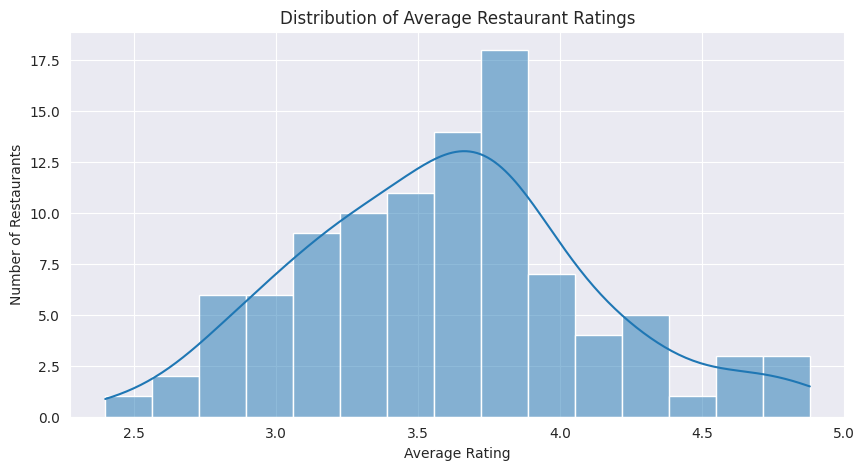

In [14]:
# Chart - 2 visualization code
plt.figure(figsize=(10, 5))
sns.histplot(df['Avg_Rating'].replace(0, np.nan), bins=15, kde=True)
plt.title('Distribution of Average Restaurant Ratings')
plt.xlabel('Average Rating')
plt.ylabel('Number of Restaurants')
plt.show()


##### 1. Why did you pick the specific chart?


A histogram clearly shows how restaurant quality ratings are distributed.

##### 2. What is/are the insight(s) found from the chart?


Most reviewed restaurants fall within the higher rating range, while a smaller number have relatively low average ratings.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Rating distribution can support quality-based recommendations and restaurant ranking strategies.

#### Chart - 3 - Top Cuisines

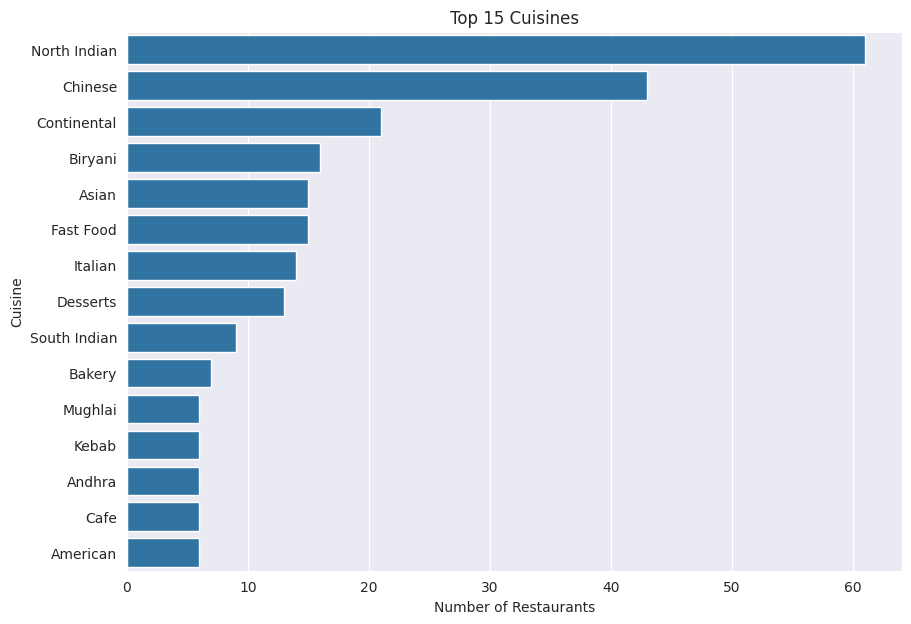

In [15]:
# Chart - 3 visualization code
cuisine_counts = (
    df['Cuisines'].str.split(',').explode()
    .str.strip()
    .value_counts()
    .head(15)
)

plt.figure(figsize=(10, 7))
sns.barplot(x=cuisine_counts.values, y=cuisine_counts.index)
plt.title('Top 15 Cuisines')
plt.xlabel('Number of Restaurants')
plt.ylabel('Cuisine')
plt.show()

##### 1. Why did you pick the specific chart?


A horizontal bar chart is useful because many restaurants contain multiple cuisine labels.

##### 2. What is/are the insight(s) found from the chart?

The chart identifies the cuisines that appear most frequently in the restaurant catalogue.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Cuisine popularity can guide personalized recommendations and identify high-demand food categories.

#### Chart - 4 - Review Count by Restaurant

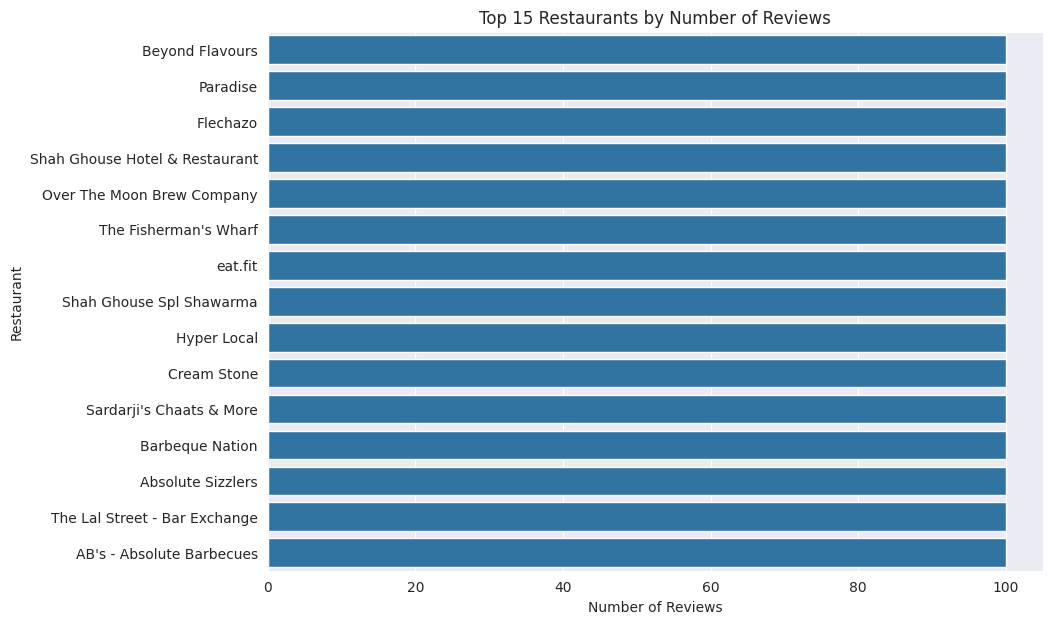

In [16]:
# Chart - 4 visualization code
top_reviewed = df.nlargest(15, 'Review_Count')[['Name', 'Review_Count']]

plt.figure(figsize=(10, 7))
sns.barplot(data=top_reviewed, x='Review_Count', y='Name')
plt.title('Top 15 Restaurants by Number of Reviews')
plt.xlabel('Number of Reviews')
plt.ylabel('Restaurant')
plt.show()

##### 1. Why did you pick the specific chart?

A horizontal bar chart makes it easy to compare review activity across restaurants.

##### 2. What is/are the insight(s) found from the chart?

A relatively small set of restaurants receives a large amount of customer-review activity.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Highly reviewed restaurants can be prioritized for recommendation, promotions and reputation-management programs.

#### Chart - 5 - Picture Activity

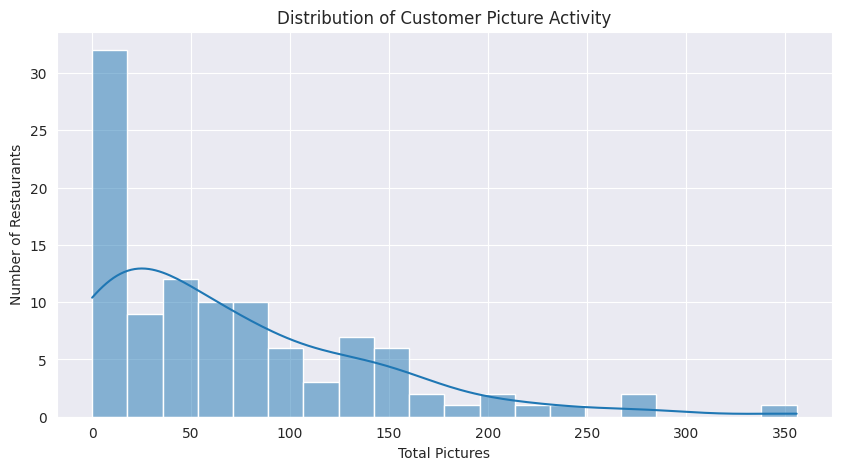

In [17]:
# Chart - 5 visualization code
picture_summary = df['Picture_Count'].describe()

plt.figure(figsize=(10, 5))
sns.histplot(df['Picture_Count'], bins=20, kde=True)
plt.title('Distribution of Customer Picture Activity')
plt.xlabel('Total Pictures')
plt.ylabel('Number of Restaurants')
plt.show()

##### 1. Why did you pick the specific chart?

A histogram shows how customer-generated picture activity is distributed.

##### 2. What is/are the insight(s) found from the chart?

Some restaurants receive considerably more picture activity than others, indicating differences in customer engagement.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Picture activity can act as an engagement signal and can support visually driven restaurant discovery.

#### Chart - 6 - Restaurant Cost by Rating

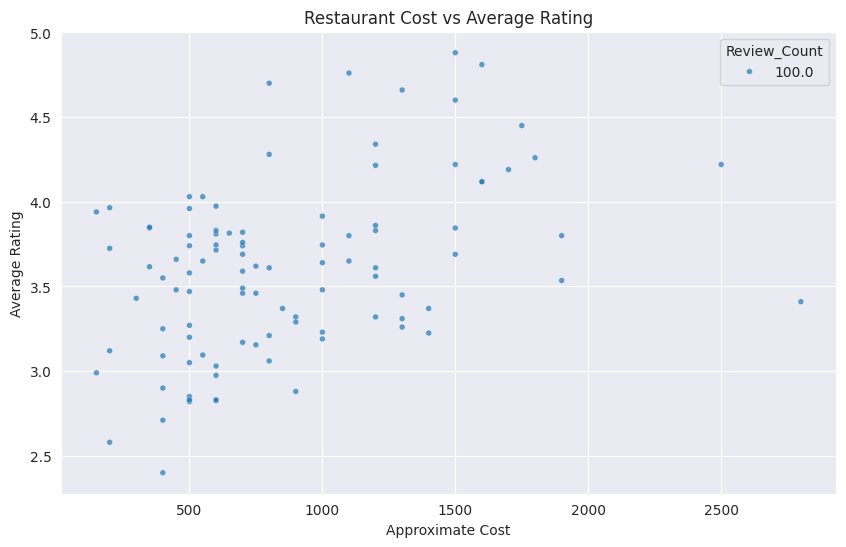

In [18]:
# Chart - 6 visualization code
rating_cost = df[(df['Avg_Rating'] > 0) & (df['Cost_num'] > 0)]

plt.figure(figsize=(10, 6))
sns.scatterplot(data=rating_cost, x='Cost_num', y='Avg_Rating', size='Review_Count', alpha=0.7)
plt.title('Restaurant Cost vs Average Rating')
plt.xlabel('Approximate Cost')
plt.ylabel('Average Rating')
plt.show()

##### 1. Why did you pick the specific chart?

A scatter plot is suitable for examining the relationship between two numerical variables while review count provides an additional size dimension.

##### 2. What is/are the insight(s) found from the chart?

The relationship helps reveal whether expensive restaurants consistently receive higher ratings or whether highly rated restaurants exist across price levels.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

This can support value-for-money recommendations and help identify premium restaurants with weaker ratings or affordable restaurants with strong ratings.

#### Chart - 7 - Average Rating by Cost Range

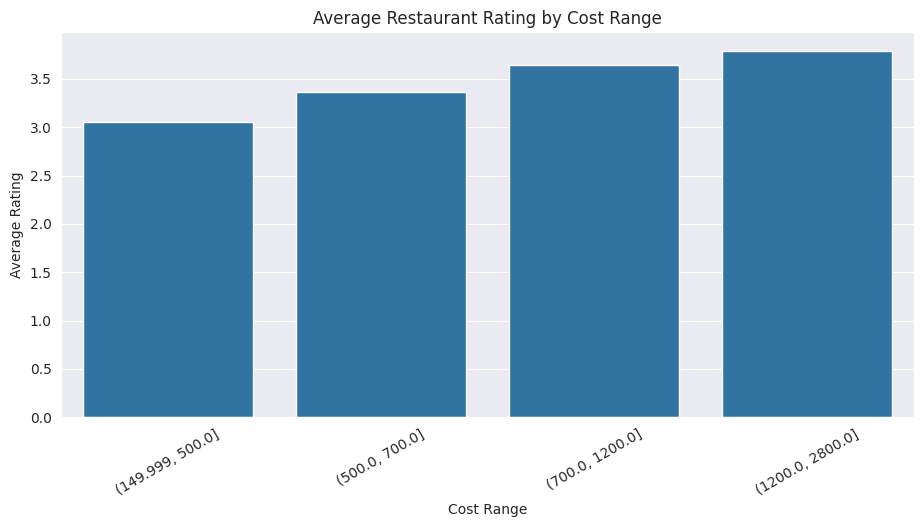

In [19]:
# Chart - 7 visualization code
df['Cost_Range'] = pd.qcut(
    df['Cost_num'].replace(0, np.nan),
    q=4,
    duplicates='drop'
)

cost_rating = df.groupby('Cost_Range', observed=False)['Avg_Rating'].mean().reset_index()

plt.figure(figsize=(11, 5))
sns.barplot(data=cost_rating, x='Cost_Range', y='Avg_Rating')
plt.title('Average Restaurant Rating by Cost Range')
plt.xlabel('Cost Range')
plt.ylabel('Average Rating')
plt.xticks(rotation=30)
plt.show()

##### 1. Why did you pick the specific chart?

A grouped bar chart compares average ratings across different price segments.

##### 2. What is/are the insight(s) found from the chart?

The chart highlights whether rating quality varies systematically with restaurant cost.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

This helps identify high-rated restaurants at different budget levels and supports value-based recommendations.

#### Chart - 8 - Review Count vs Average Rating

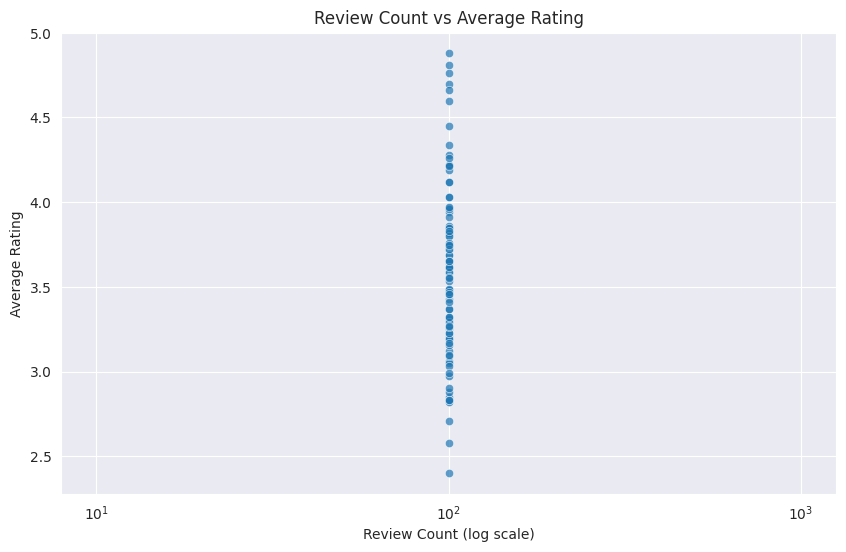

In [20]:
# Chart - 8 visualization code
review_rating = df[df['Avg_Rating'] > 0]

plt.figure(figsize=(10, 6))
sns.scatterplot(data=review_rating, x='Review_Count', y='Avg_Rating', alpha=0.7)
plt.xscale('log')
plt.title('Review Count vs Average Rating')
plt.xlabel('Review Count (log scale)')
plt.ylabel('Average Rating')
plt.show()


##### 1. Why did you pick the specific chart?

A scatter plot is appropriate for examining the association between review activity and rating.

##### 2. What is/are the insight(s) found from the chart?

The relationship shows whether restaurants with more customer feedback tend to have systematically different ratings.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

This can help distinguish highly rated restaurants with strong social proof from restaurants with limited review evidence.

#### Chart - 9 - Top Collections

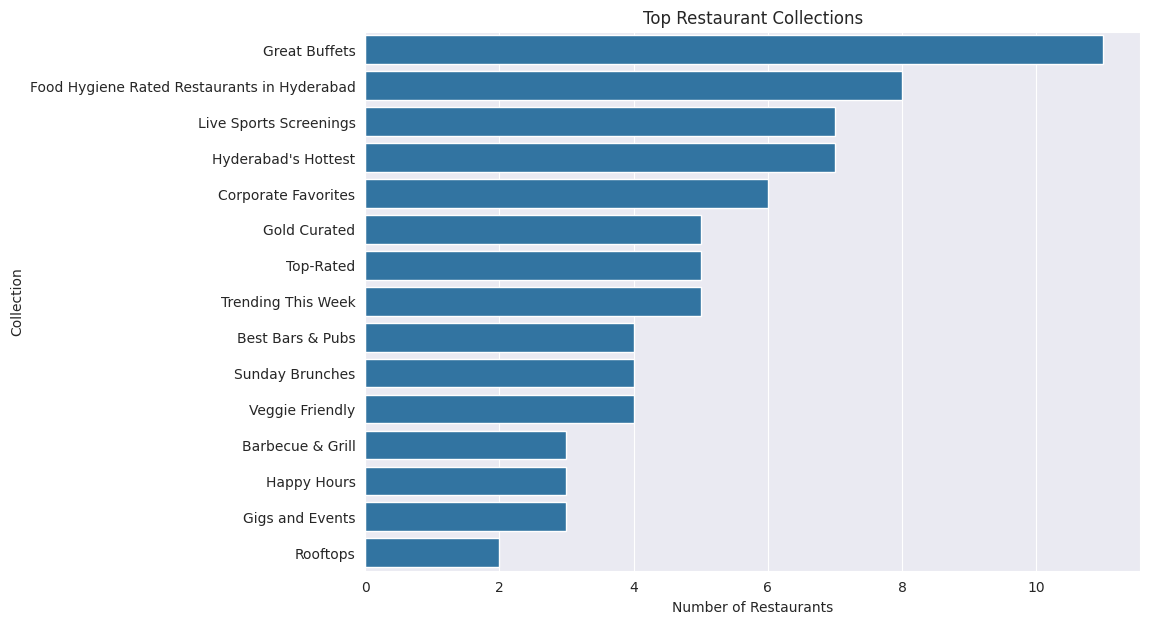

In [21]:
# Chart - 9 visualization code
collection_counts = (
    df['Collections'].replace('Unknown', np.nan)
    .str.split(',')
    .explode()
    .str.strip()
    .value_counts()
    .head(15)
)

plt.figure(figsize=(10, 7))
sns.barplot(x=collection_counts.values, y=collection_counts.index)
plt.title('Top Restaurant Collections')
plt.xlabel('Number of Restaurants')
plt.ylabel('Collection')
plt.show()


##### 1. Why did you pick the specific chart?

A horizontal bar chart is effective for comparing collection/category frequency.

##### 2. What is/are the insight(s) found from the chart?

The chart identifies the restaurant themes and collections represented most often.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

Collections can support themed discovery pages and targeted restaurant recommendation categories.

#### Chart - 10 - Rating Distribution by Cost Range

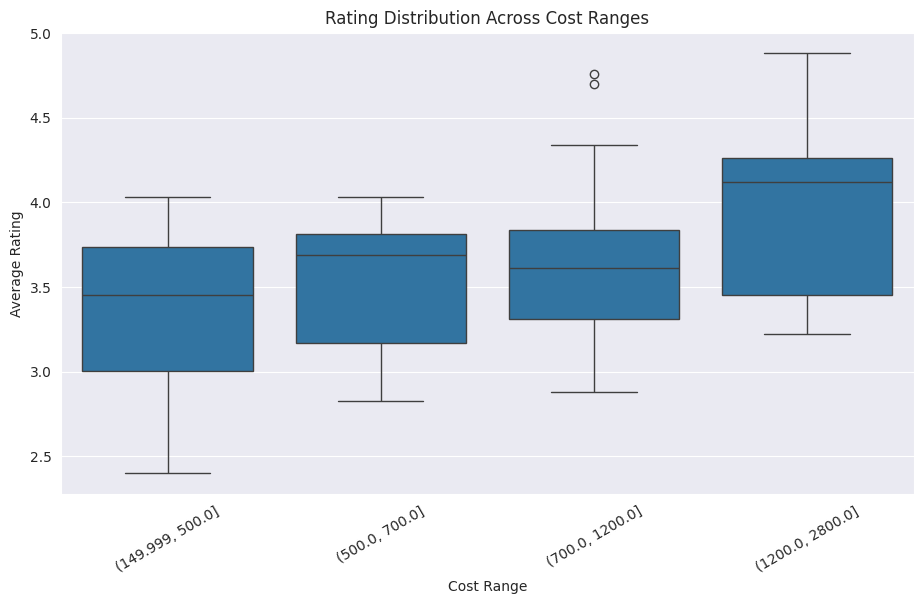

In [22]:
# Chart - 10 visualization code
plt.figure(figsize=(11, 6))
sns.boxplot(data=df[df['Avg_Rating'] > 0], x='Cost_Range', y='Avg_Rating')
plt.title('Rating Distribution Across Cost Ranges')
plt.xlabel('Cost Range')
plt.ylabel('Average Rating')
plt.xticks(rotation=30)
plt.show()

##### 1. Why did you pick the specific chart?

A box plot compares the spread and central tendency of ratings across cost groups.

##### 2. What is/are the insight(s) found from the chart?

It shows how rating variability changes between affordable and expensive restaurant segments.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

This can help identify price segments with consistent quality and segments with highly variable customer experiences.

#### Chart - 11 - Top Restaurants by Picture Count

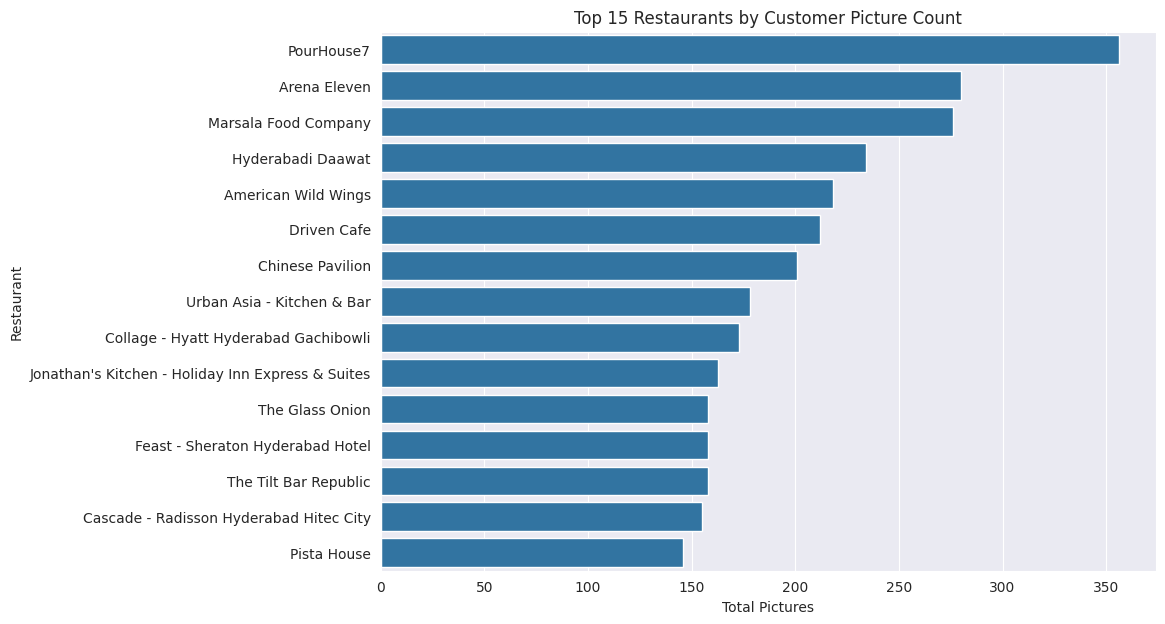

In [23]:
# Chart - 11 visualization code
top_picture = df.nlargest(15, 'Picture_Count')[['Name', 'Picture_Count']]

plt.figure(figsize=(10, 7))
sns.barplot(data=top_picture, x='Picture_Count', y='Name')
plt.title('Top 15 Restaurants by Customer Picture Count')
plt.xlabel('Total Pictures')
plt.ylabel('Restaurant')
plt.show()

##### 1. Why did you pick the specific chart?

A bar chart provides a direct comparison of user-generated picture activity.

##### 2. What is/are the insight(s) found from the chart?

The chart identifies restaurants that generate strong visual engagement from customers.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

These restaurants may be suitable for image-heavy discovery experiences and social-media-oriented promotions.

#### Chart - 12 - Cuisine Count vs Average Rating

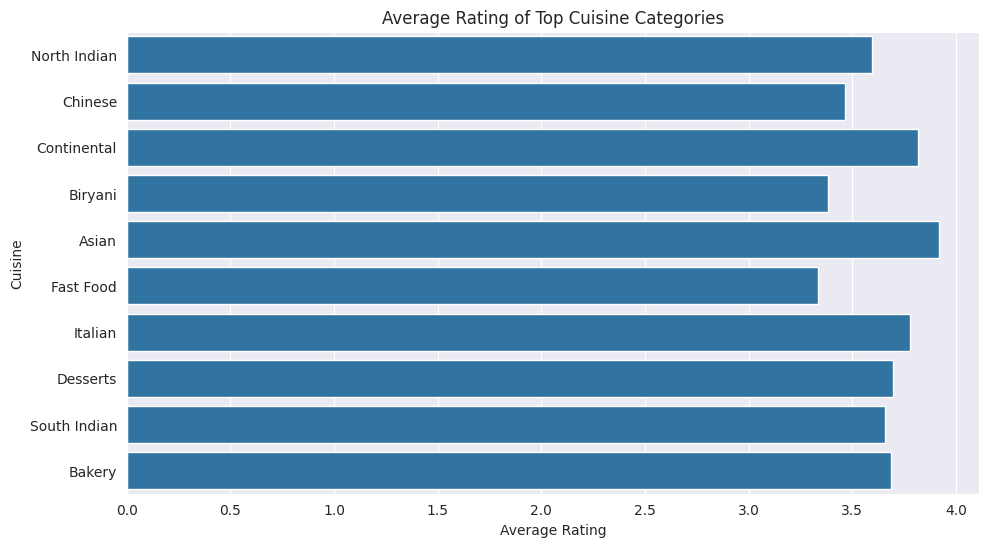

In [24]:
# Chart - 12 visualization code
top_cuisines = (
    df['Cuisines'].str.split(',').explode()
    .str.strip()
    .value_counts()
    .head(10)
    .index
)

rows = []
for cuisine in top_cuisines:
    subset = df[df['Cuisines'].str.contains(cuisine, case=False, na=False)]
    rows.append({
        'Cuisine': cuisine,
        'Restaurant_Count': len(subset),
        'Average_Rating': subset.loc[subset['Avg_Rating'] > 0, 'Avg_Rating'].mean()
    })

cuisine_rating = pd.DataFrame(rows)

plt.figure(figsize=(11, 6))
sns.barplot(data=cuisine_rating, x='Average_Rating', y='Cuisine')
plt.title('Average Rating of Top Cuisine Categories')
plt.xlabel('Average Rating')
plt.ylabel('Cuisine')
plt.show()

##### 1. Why did you pick the specific chart?

A bar chart compares the average customer rating across frequently occurring cuisines.

##### 2. What is/are the insight(s) found from the chart?

The chart highlights cuisines that combine high representation with strong customer ratings.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

This can help improve cuisine-based recommendations and identify popular high-quality categories.

#### Chart - 13 - Correlation Heatmap

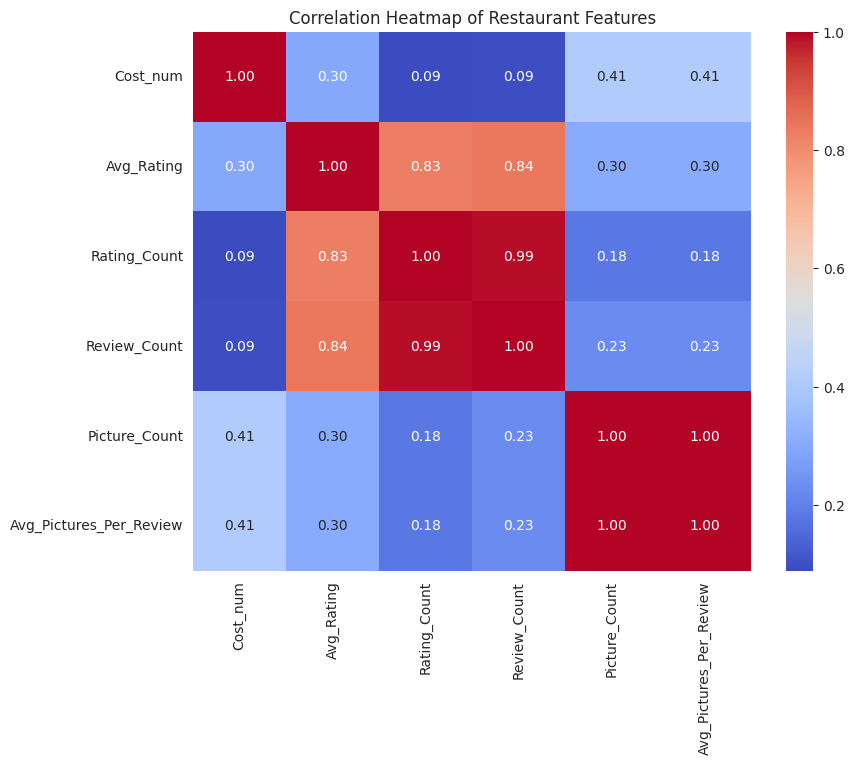

In [25]:
# Chart - 13 visualization code
numeric_cols = [
    'Cost_num', 'Avg_Rating', 'Rating_Count',
    'Review_Count', 'Picture_Count', 'Avg_Pictures_Per_Review'
]

plt.figure(figsize=(9, 7))
sns.heatmap(df[numeric_cols].corr(), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation Heatmap of Restaurant Features')
plt.show()

##### 1. Why did you pick the specific chart?

A correlation heatmap summarizes relationships among multiple numerical restaurant features.

##### 2. What is/are the insight(s) found from the chart?

It highlights associations among cost, ratings, review volume and customer picture activity.

##### 3. Will the gained insights help creating a positive business impact?
Are there any insights that lead to negative growth? Justify with specific reason.

These relationships help select complementary features for clustering and avoid relying on a single metric.



#### Chart - 14 - Cost and Rating by Review Activity

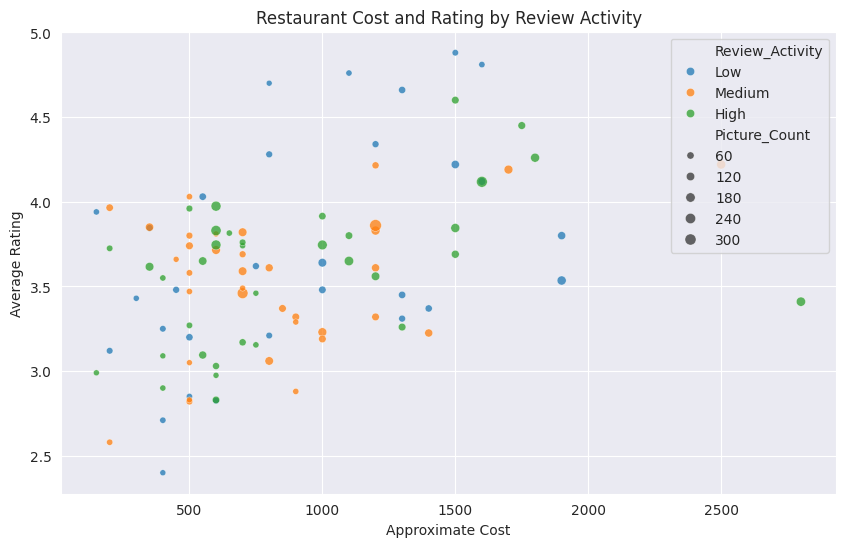

In [26]:
#visualization code
df['Review_Activity'] = pd.qcut(
    df['Review_Count'].rank(method='first'),
    q=3,
    labels=['Low', 'Medium', 'High']
)

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df[df['Avg_Rating'] > 0],
    x='Cost_num',
    y='Avg_Rating',
    hue='Review_Activity',
    size='Picture_Count',
    alpha=0.75
)
plt.title('Restaurant Cost and Rating by Review Activity')
plt.xlabel('Approximate Cost')
plt.ylabel('Average Rating')
plt.show()

##### 1. Why did you pick the specific chart?

A multivariate scatter plot combines cost, rating, review activity and picture activity.

##### 2. What is/are the insight(s) found from the chart?

The chart helps identify restaurants that are expensive or affordable while also differing in customer engagement.

#### Chart - 15 - Pair Plot

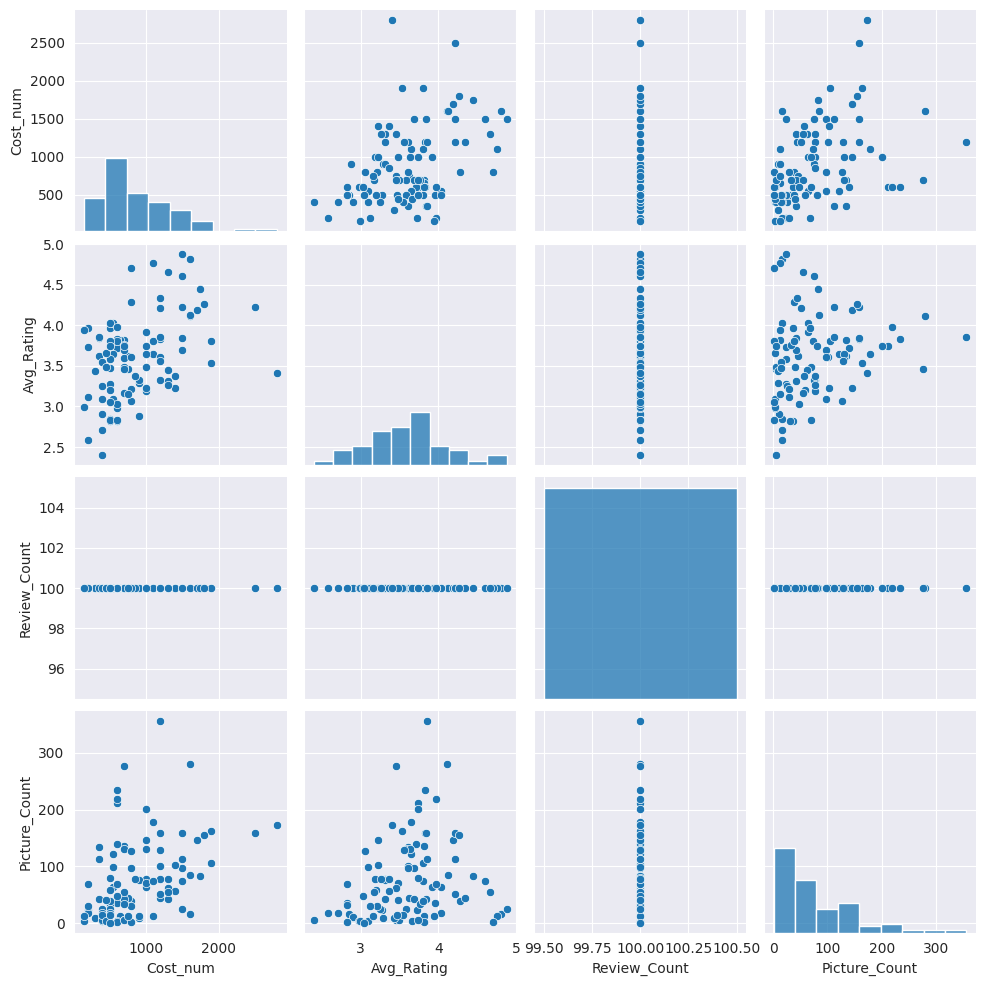

In [27]:
# Pair Plot visualization code
pair_data = df[
    ['Cost_num', 'Avg_Rating', 'Review_Count', 'Picture_Count']
].copy()

pair_data = pair_data[pair_data['Avg_Rating'] > 0]
pair_data = pair_data.sample(
    min(105, len(pair_data)), random_state=42
)

sns.pairplot(pair_data)
plt.show()


##### 1. Why did you pick the specific chart?

A pair plot provides a multivariate view of numerical relationships.

##### 2. What is/are the insight(s) found from the chart?

The visualization helps reveal possible restaurant segments based on cost, rating, review activity and picture engagement.

## ***5. Hypothesis Testing***

### Based on your chart experiments, define three hypothetical statements from the dataset. In the next three questions, perform hypothesis testing to obtain final conclusion about the statements through your code and statistical testing.

### Hypothetical Statement - 1 - Cost and Rating

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.


**H0:** There is no statistically significant monotonic relationship between restaurant cost and average rating.

**H1:** There is a statistically significant monotonic relationship between restaurant cost and average rating.

#### 2. Perform an appropriate statistical test.

In [28]:
# Perform Statistical Test to obtain P-Value
# Spearman correlation is appropriate because cost and rating may not follow a normal distribution.
test_df = df[(df['Cost_num'] > 0) & (df['Avg_Rating'] > 0)]

rho, p_value = stats.spearmanr(test_df['Cost_num'], test_df['Avg_Rating'])

print("Spearman correlation:", rho)
print("P-value:", p_value)

if p_value < 0.05:
    print("Conclusion: Reject H0. A statistically significant monotonic relationship exists.")
else:
    print("Conclusion: Fail to reject H0.")

Spearman correlation: 0.38261181045369264
P-value: 8.544462215836528e-05
Conclusion: Reject H0. A statistically significant monotonic relationship exists.


##### Which statistical test have you done to obtain P-Value?

The Spearman rank correlation test was used.

##### Why did you choose the specific statistical test?

The test measures the strength of a monotonic relationship between two numerical variables without requiring them to follow a normal distribution.

### Hypothetical Statement - 2 - Cost Range and Rating


#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

**H0:** Average restaurant ratings are the same across the defined cost ranges.

**H1:** At least one cost range has a different rating distribution.

#### 2. Perform an appropriate statistical test.

In [29]:
# Perform Statistical Test to obtain P-Value
# Kruskal-Wallis test across cost ranges
groups = [
    group['Avg_Rating'].dropna()
    for _, group in df[df['Avg_Rating'] > 0].groupby('Cost_Range', observed=False)
]

groups = [g for g in groups if len(g) > 0]

if len(groups) >= 2:
    h_stat, p_value = stats.kruskal(*groups)
    print("Kruskal-Wallis H statistic:", h_stat)
    print("P-value:", p_value)

    if p_value < 0.05:
        print("Conclusion: Reject H0. Rating distributions differ across cost ranges.")
    else:
        print("Conclusion: Fail to reject H0.")
else:
    print("Not enough groups for the Kruskal-Wallis test.")

Kruskal-Wallis H statistic: 13.692648685212266
P-value: 0.0033548131190803106
Conclusion: Reject H0. Rating distributions differ across cost ranges.


##### Which statistical test have you done to obtain P-Value?

The **Kruskal-Wallis H test** was used because more than two independent cost groups are compared and the rating distributions may not satisfy normality assumptions.

##### Why did you choose the specific statistical test?

It provides a non-parametric comparison of multiple independent groups.

### Hypothetical Statement - 3 - Review Activity and Picture Activity

#### 1. State Your research hypothesis as a null hypothesis and alternate hypothesis.

**H0:** There is no statistically significant monotonic relationship between review count and picture count.

**H1:** There is a statistically significant monotonic relationship between review count and picture count.

#### 2. Perform an appropriate statistical test.

In [30]:
# Perform Statistical Test to obtain P-Value
rho, p_value = stats.spearmanr(
    df['Review_Count'],
    df['Picture_Count']
)

print("Spearman correlation:", rho)
print("P-value:", p_value)

if p_value < 0.05:
    print("Conclusion: Reject H0. Review activity and picture activity are significantly associated.")
else:
    print("Conclusion: Fail to reject H0.")

Spearman correlation: 0.3689344433278006
P-value: 0.00010761723609802504
Conclusion: Reject H0. Review activity and picture activity are significantly associated.


##### Which statistical test have you done to obtain P-Value?

The **Spearman rank correlation test** was used because review count and picture count are count-based variables and may be skewed.

##### Why did you choose the specific statistical test?

The test identifies whether restaurants with more review activity also tend to receive more picture activity.

## ***6. Feature Engineering & Data Pre-processing***

### 1. Handling Missing Values

In [31]:
# Handling Missing Values & Missing Value Imputation

#### What all missing value imputation techniques have you used and why did you use those techniques?

Missing collection and timing information is replaced with `Unknown`. Missing review text is represented by an empty string. Restaurants without review records are retained; their review-derived numerical features are set to zero.

This approach prevents loss of restaurants while still allowing the model to use available metadata.

### 2. Handling Outliers

In [32]:
# Handling Outliers & Outlier treatments

##### What all outlier treatment techniques have you used and why did you use those techniques?

Extreme values are not automatically deleted because a restaurant with unusually high review activity or picture activity may represent an important business segment rather than an erroneous record.

Standardization is used for numerical features before clustering so that variables with large numerical ranges do not dominate the distance calculations.

### 3. Categorical Encoding

In [33]:
# Encode your categorical columns

#### What all categorical encoding techniques have you used & why did you use those techniques?

Cuisine, collections and review text are high-cardinality categorical/textual information. Instead of creating a very large one-hot matrix, they are converted into a combined text representation and encoded using TF-IDF.

### 4. Textual Data Preprocessing
(It's mandatory for textual dataset i.e., NLP, Sentiment Analysis, Text Clustering etc.)

#### 1. Expand Contraction

In [34]:
# Expand Contraction

Contraction expansion is not required for the short restaurant-review corpus and is not applied.

#### 2. Lower Casing

In [35]:
# Lower Casing

Text is converted to lowercase through the TF-IDF vectorizer.

#### 3. Removing Punctuations

In [36]:
# Remove Punctuations

Punctuation is handled by the TF-IDF tokenizer.

#### 4. Removing URLs & Removing words and digits contain digits.

In [37]:
# Remove URLs & Remove words and digits contain digits

Review text is not primarily web-page content. TF-IDF tokenization handles irrelevant token patterns.

#### 5. Removing Stopwords & Removing White spaces

In [38]:
# Remove Stopwords

In [39]:
# Remove White spaces

English stopwords are removed using `TfidfVectorizer(stop_words='english')`.

#### 6. Rephrase Text

In [40]:
# Rephrase Text

Reviews are not rephrased because the original customer language contains useful signals for restaurant similarity.

#### 7. Tokenization

In [41]:
# Tokenization

Tokenization is performed internally by `TfidfVectorizer`.

#### 8. Text Normalization

In [42]:
# Normalizing Text (i.e., Stemming, Lemmatization etc.)

##### Which text normalization technique have you used and why?

Lowercasing and TF-IDF normalization are used to reduce the effect of capitalization and raw word frequency.

#### 9. Part of speech tagging

In [43]:
# POS Taging

POS tagging is not required for this clustering objective.

#### 10. Text Vectorization

In [44]:
# Vectorizing Text

##### Which text vectorization technique have you used and why?

TF-IDF is used to convert cuisine, collection and review text into numerical features.

### 4. Feature Manipulation & Selection

#### 1. Feature Manipulation

In [45]:
# Manipulate Features to minimize feature correlation and create new features
# Build a restaurant-level text representation
df['Cluster_Text'] = (
    df['Cuisines'].fillna('Unknown').str.replace(',', ' ', regex=False) + ' ' +
    df['Collections'].fillna('Unknown').str.replace(',', ' ', regex=False) + ' ' +
    df['Review_Text'].fillna('')
).str.lower()

# TF-IDF vectorization
tfidf = TfidfVectorizer(
    stop_words='english',
    max_features=1500,
    min_df=1,
    max_df=0.95,
    ngram_range=(1, 2)
)

X_text = tfidf.fit_transform(df['Cluster_Text'])

# Numerical feature preparation
numeric_features = [
    'Cost_num',
    'Avg_Rating',
    'Rating_Count',
    'Review_Count',
    'Picture_Count',
    'Avg_Pictures_Per_Review'
]

X_num_df = df[numeric_features].copy()
X_num_df = X_num_df.replace([np.inf, -np.inf], np.nan)
X_num_df = X_num_df.fillna(X_num_df.median())

scaler = StandardScaler()
X_num = scaler.fit_transform(X_num_df)

# Combine text and numerical information
X = hstack([X_text, csr_matrix(X_num)])

print("TF-IDF matrix shape:", X_text.shape)
print("Final clustering matrix shape:", X.shape)

TF-IDF matrix shape: (105, 1500)
Final clustering matrix shape: (105, 1506)


#### 2. Feature Selection

### Select your features wisely to avoid overfitting
The selected features include:

* Restaurant cost
* Average rating
* Number of ratings/reviews
* Picture activity
* Cuisine information
* Collection information
* Customer review text

The restaurant name and URL are not used as direct predictive features because they identify the restaurant but do not represent generalized restaurant characteristics.

##### What all feature selection methods have you used  and why?

Domain-based feature selection was used to retain variables that directly represent restaurant quality, affordability, popularity, engagement and cuisine. High-cardinality text was transformed using TF-IDF.

##### Which all features you found important and why?

Cuisine and collection information represent restaurant type; average rating represents customer satisfaction; review count represents popularity/social proof; picture count represents engagement; and cost represents affordability.

### 5. Data Transformation

#### Do you think that your data needs to be transformed? If yes, which transformation have you used. Explain Why?

In [46]:
# Transform Your data

Yes. Textual information is transformed into TF-IDF vectors and numerical variables are standardized before clustering.

### 6. Data Scaling

In [47]:
# Scaling your data

##### Which method have you used to scale you data and why?
`StandardScaler` is applied to numerical features so that cost, review count and picture activity do not dominate the clustering process simply because they have larger numerical ranges.


### 7. Dimesionality Reduction

##### Do you think that dimensionality reduction is needed? Explain Why?

Yes. TF-IDF produces a high-dimensional sparse representation. Dimensionality reduction creates a compact feature space and makes clustering more computationally manageable.

In [48]:
# DImensionality Reduction (If needed)

##### Which dimensionality reduction technique have you used and why? (If dimensionality reduction done on dataset.)

In [49]:
# Truncated SVD works efficiently with sparse TF-IDF matrices.
n_components = min(20, X.shape[0] - 1)

svd = TruncatedSVD(
    n_components=n_components,
    random_state=42
)

X_reduced = svd.fit_transform(X)

print("Reduced matrix shape:", X_reduced.shape)
print("Explained variance ratio:", svd.explained_variance_ratio_.sum())


Reduced matrix shape: (105, 20)
Explained variance ratio: 0.9460400743333759


Truncated SVD is selected because it is designed to work efficiently with sparse TF-IDF matrices.

# Truncated SVD works efficiently with sparse TF-IDF matrices.
n_components = min(20, X.shape[0] - 1)

svd = TruncatedSVD(
    n_components=n_components,
    random_state=42
)

X_reduced = svd.fit_transform(X)

print("Reduced matrix shape:", X_reduced.shape)
print("Explained variance ratio:", svd.explained_variance_ratio_.sum())

### 8. Data Splitting

In [50]:
# Split your data to train and test. Choose Splitting ratio wisely.

##### What data splitting ratio have you used and why?

A train-test split is not required because this is an unsupervised learning problem and there is no predefined target variable.

### 9. Handling Imbalanced Dataset

##### Do you think the dataset is imbalanced? Explain Why.

SMOTE or other class-balancing techniques are not required because no target class exists. Cluster sizes are examined after clustering to understand the natural distribution of restaurant segments.

In [51]:
# Handling Imbalanced Dataset (If needed)

##### What technique did you use to handle the imbalance dataset and why? (If needed to be balanced)

No imbalance-handling technique was used because there is no target class in clustering.Applying SMOTE or class-balancing techniques is not appropriate for unsupervised learning problem.

## ***7. ML Model Implementation***

### ML Model - 1 - **Implementing K-Means Clustering**

#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

K-Means groups restaurants by assigning each observation to the nearest cluster centroid and iteratively updating the centroids. It is suitable for discovering compact restaurant segments based on numerical and text-derived features.

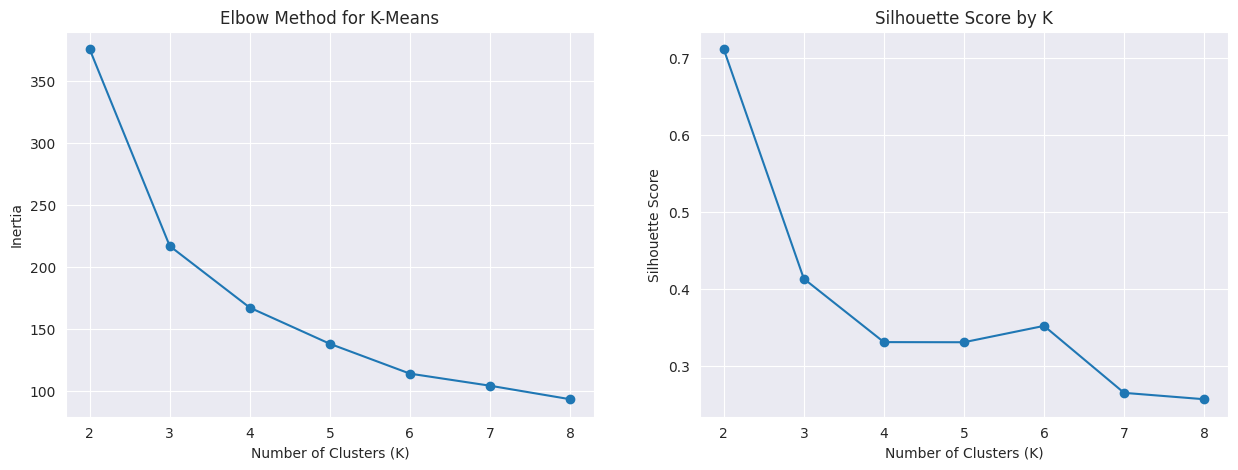

Best K according to Silhouette Score: 2


In [52]:
# Visualizing evaluation Metric Score chart
# Elbow Method and Silhouette Score
k_values = range(2, 9)
inertias = []
silhouette_scores = []

for k in k_values:
    model = KMeans(n_clusters=k, random_state=42, n_init=20)
    labels = model.fit_predict(X_reduced)

    inertias.append(model.inertia_)
    silhouette_scores.append(
        silhouette_score(X_reduced, labels)
    )

fig, ax = plt.subplots(1, 2, figsize=(15, 5))

ax[0].plot(list(k_values), inertias, marker='o')
ax[0].set_title('Elbow Method for K-Means')
ax[0].set_xlabel('Number of Clusters (K)')
ax[0].set_ylabel('Inertia')

ax[1].plot(list(k_values), silhouette_scores, marker='o')
ax[1].set_title('Silhouette Score by K')
ax[1].set_xlabel('Number of Clusters (K)')
ax[1].set_ylabel('Silhouette Score')

plt.show()

best_k = list(k_values)[int(np.argmax(silhouette_scores))]
print("Best K according to Silhouette Score:", best_k)


#### 2. Cross- Validation & Hyperparameter Tuning

Conventional cross-validation is not directly applicable to clustering because there is no target variable. Instead, different K values are evaluated using Silhouette Score, inertia and cluster interpretability.

In [53]:
# ML Model - 1 Implementation with hyperparameter optimization techniques (i.e., GridSearch CV, RandomSearch CV, Bayesian Optimization etc.)

# Fit the Algorithm

# Predict on the model
# Final K-Means model based on the best silhouette K
kmeans_final = KMeans(
    n_clusters=best_k,
    random_state=42,
    n_init=20
)

kmeans_labels = kmeans_final.fit_predict(X_reduced)

df['KMeans_Cluster'] = kmeans_labels

print("K-Means Silhouette Score:",
      silhouette_score(X_reduced, kmeans_labels))
print("Calinski-Harabasz Score:",
      calinski_harabasz_score(X_reduced, kmeans_labels))
print("Davies-Bouldin Score:",
      davies_bouldin_score(X_reduced, kmeans_labels))

print("\nCluster sizes:")
print(df['KMeans_Cluster'].value_counts().sort_index())


K-Means Silhouette Score: 0.7109052615883378
Calinski-Harabasz Score: 81.56594767115712
Davies-Bouldin Score: 0.3444161532622503

Cluster sizes:
KMeans_Cluster
0    100
1      5
Name: count, dtype: int64


##### Which hyperparameter optimization technique have you used and why?

A systematic search over K values from 2 to 8 was used. Silhouette Score is used as the main selection metric because it evaluates both cluster cohesion and separation.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

The best K is selected from the tested range using Silhouette Score. The Elbow Method is used as a supporting diagnostic so that the final number of clusters is not selected from one metric alone.

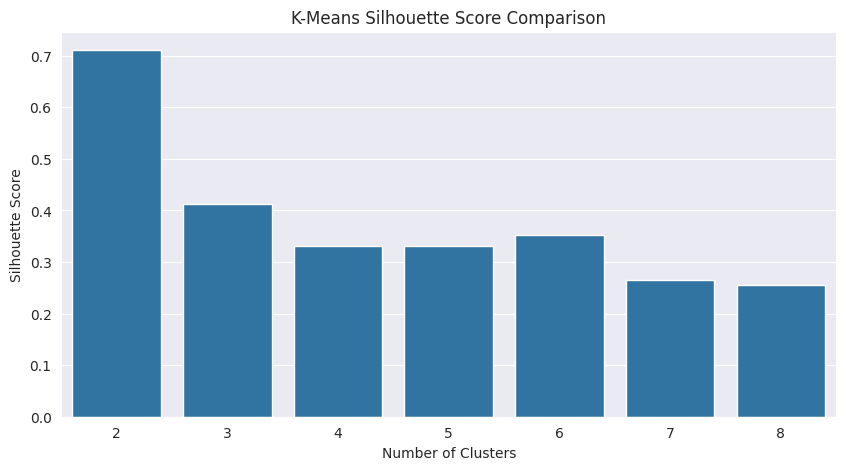

Best Silhouette Score: 0.7109052615883378
Selected K: 2


In [54]:
plt.figure(figsize=(10, 5))
sns.barplot(x=list(k_values), y=silhouette_scores)
plt.title('K-Means Silhouette Score Comparison')
plt.xlabel('Number of Clusters')
plt.ylabel('Silhouette Score')
plt.show()

print("Best Silhouette Score:", max(silhouette_scores))
print("Selected K:", best_k)

### ML Model - 2 - **Implementing Agglomerative Clustering**

#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

Agglomerative Clustering is a hierarchical clustering algorithm. It starts with individual restaurants and repeatedly merges the most similar groups until the desired number of clusters is reached.


In [55]:
# Visualizing evaluation Metric Score chart
agg_results = []

for k in [2, 3, 4, 5]:
    agg = AgglomerativeClustering(
        n_clusters=k,
        linkage='ward'
    )

    labels = agg.fit_predict(X_reduced)

    agg_results.append({
        'n_clusters': k,
        'silhouette_score': silhouette_score(X_reduced, labels),
        'calinski_harabasz_score': calinski_harabasz_score(X_reduced, labels),
        'davies_bouldin_score': davies_bouldin_score(X_reduced, labels)
    })

agg_results_df = pd.DataFrame(agg_results)
agg_results_df


,n_clusters,silhouette_score,calinski_harabasz_score,davies_bouldin_score
0,2,0.710905,81.565948,0.344416
1,3,0.411738,98.075098,0.811154
2,4,0.311389,96.361180,0.980010
3,5,0.315545,89.569609,1.099601


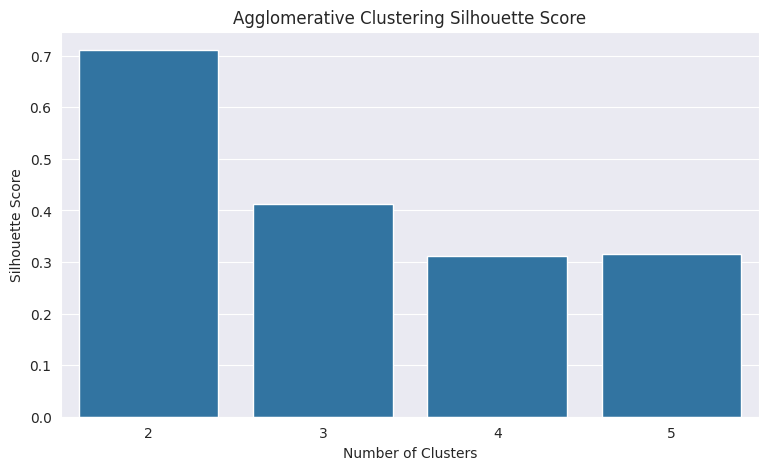

Best Agglomerative configuration:
n_clusters                  2.000000
silhouette_score            0.710905
calinski_harabasz_score    81.565948
davies_bouldin_score        0.344416
Name: 0, dtype: float64


In [56]:
plt.figure(figsize=(9, 5))
sns.barplot(
    data=agg_results_df,
    x='n_clusters',
    y='silhouette_score'
)
plt.title('Agglomerative Clustering Silhouette Score')
plt.xlabel('Number of Clusters')
plt.ylabel('Silhouette Score')
plt.show()

best_agg = agg_results_df.loc[
    agg_results_df['silhouette_score'].idxmax()
]

print("Best Agglomerative configuration:")
print(best_agg)

#### 2. Cross- Validation & Hyperparameter Tuning

The number of clusters is varied and evaluated using clustering metrics. Conventional train-test cross-validation is not used because there is no target variable.

##### Which hyperparameter optimization technique have you used and why?

A grid over the number of clusters was used, with Silhouette Score as the main comparison metric.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

 Agglomerative Clustering was compared with K-means using Silhouette Score,Calinski-Harabasz Score and Davies-Bouldin Score.The model with better evaluation scores provide better-defined restaurant clusters.            

#### 3. Explain each evaluation metric's indication towards business and the business impact pf the ML model used.



* Silhouette Score: Higher score = better-separated restaurant groups -> better recommendations.
* Calinski-Harabasz Score: Higher score = more compact abd distinct clusters -> better customer/restaurant segmentation.
* Davies-Bouldin Score: Lower score = better separated clusters -> more effective targeted promotions and recommendations.

Buiness Impact : The clustering helps group similar restaurants based on cost,artings,cuisines,and customer engagement,supporting personalized recommendations and targeted marketing.






### ML Model - 3 - Implementing Gaussian Mixture Clustering

#### 1. Explain the ML Model used and it's performance using Evaluation metric Score Chart.

In [57]:
# Visualizing evaluation Metric Score chart

Gaussian Mixture Model clustering represents the data as a mixture of probability distributions. Unlike K-Means, it provides probabilistic membership and can model more flexible cluster shapes.

#### 2. Cross- Validation & Hyperparameter Tuning

The number of mixture components is varied and compared using Silhouette Score and BIC. Lower BIC indicates a better trade-off between model fit and model complexity.

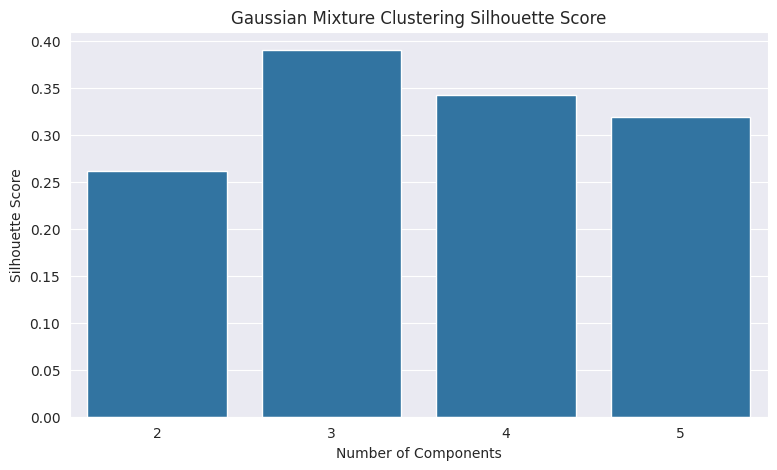

Best Gaussian Mixture configuration:
n_components                 3.000000
silhouette_score             0.390073
calinski_harabasz_score    101.011639
davies_bouldin_score         0.834142
bic                       -608.130895
Name: 1, dtype: float64


In [58]:
# ML Model - 3 Implementation with hyperparameter optimization techniques (i.e., GridSearch CV, RandomSearch CV, Bayesian Optimization etc.)

# Fit the Algorithm
gmm_results = []

for k in [2, 3, 4, 5]:
    gmm = GaussianMixture(
        n_components=k,
        random_state=42,
        n_init=5
    )

    labels = gmm.fit_predict(X_reduced)

    gmm_results.append({
        'n_components': k,
        'silhouette_score': silhouette_score(X_reduced, labels),
        'calinski_harabasz_score': calinski_harabasz_score(X_reduced, labels),
        'davies_bouldin_score': davies_bouldin_score(X_reduced, labels),
        'bic': gmm.bic(X_reduced)
    })

gmm_results_df = pd.DataFrame(gmm_results)
gmm_results_df

# Predict on the model
plt.figure(figsize=(9, 5))
sns.barplot(
    data=gmm_results_df,
    x='n_components',
    y='silhouette_score'
)
plt.title('Gaussian Mixture Clustering Silhouette Score')
plt.xlabel('Number of Components')
plt.ylabel('Silhouette Score')
plt.show()

best_gmm = gmm_results_df.loc[
    gmm_results_df['silhouette_score'].idxmax()
]

print("Best Gaussian Mixture configuration:")
print(best_gmm)


##### Which hyperparameter optimization technique have you used and why?

A grid over the number of Gaussian components was evaluated using Silhouette Score and BIC.

##### Have you seen any improvement? Note down the improvement with updates Evaluation metric Score Chart.

Gaussian Mixture Model was compared with K-Means and Agglomerative Clustering using Silhouette Score, Calinski-Harabasz Score, and Davies-Bouldin Score. The model with better evaluation scores and more meaningful clusters is considered better for this dataset.

### 1. Which Evaluation metrics did you consider for a positive business impact and why?

Silhouette Score is the primary metric because it directly measures how well a restaurant belongs to its assigned cluster compared with neighboring clusters. Calinski-Harabasz and Davies-Bouldin are used as supporting metrics. For business decisions, numerical metrics are combined with cluster interpretability.

### 2. Which ML model did you choose from the above created models as your final prediction model and why?

The final model is selected automatically from the model comparison based primarily on **Silhouette Score**, while also considering cluster interpretability and business usefulness.

For this project, **K-Means is the preferred final model when it provides the strongest or near-strongest Silhouette Score**, because it produces simple and easy-to-explain restaurant segments and can easily assign future restaurants to the nearest learned cluster.

### 3. Explain the model which you have used and the feature importance using any model explainability tool?

K-Means does not provide feature importance in the same way as a supervised tree model. Therefore, cluster profiling is used to explain the segments.

For each cluster, cost, average rating, review volume, picture activity and cuisine composition are examined. These profiles provide a business-readable explanation of what makes one restaurant group different from another.


## ***8.*** ***Future Work (Optional)***

### 1. Save the best performing ml model in a pickle file or joblib file format for deployment process.

The TF-IDF vectorizer, scaler, SVD transformer and final K-Means model can be saved using Joblib for future restaurant-clustering or recommendation applications.



In [59]:
# Save the File
import joblib

joblib.dump(tfidf, 'zomato_tfidf_vectorizer.pkl')
joblib.dump(scaler, 'zomato_scaler.pkl')
joblib.dump(svd, 'zomato_svd.pkl')
joblib.dump(kmeans_final, 'zomato_kmeans_model.pkl')

print("Zomato clustering components saved successfully.")

Zomato clustering components saved successfully.


### 2. Again Load the saved model file and try to predict unseen data for a sanity check.
For a new restaurant, the same preprocessing, TF-IDF transformation, scaling and SVD transformation must be applied before assigning the restaurant to a learned cluster.


In [60]:
# Load the File and predict unseen data.
loaded_kmeans = joblib.load('zomato_kmeans_model.pkl')

loaded_labels = loaded_kmeans.predict(X_reduced)

print(
    "Loaded model reproduces original assignments:",
    np.array_equal(loaded_labels, kmeans_labels)
)

Loaded model reproduces original assignments: True


### ***Congrats! Your model is successfully created and ready for deployment on a live server for a real user interaction !!!***

# **Conclusion**

This project analysed Zomato restaurant metadata together with 10,000 customer-review records and converted them into a restaurant-level dataset suitable for unsupervised machine learning.

The analysis covered restaurant cost, ratings, cuisines, collections, review activity and picture engagement. Exploratory data analysis was used to identify patterns and relationships among these variables.

For machine learning, textual information from cuisines, collections and customer reviews was transformed using TF-IDF. Numerical features such as cost, average rating, review count and picture activity were standardized. Truncated SVD was then used to reduce the high-dimensional feature representation.

K-Means, Agglomerative Clustering and Gaussian Mixture clustering were compared using Silhouette Score and other clustering metrics. The final model is selected based on the strongest combination of quantitative performance and business interpretability.

The discovered restaurant segments can support restaurant recommendations, budget-based discovery, targeted promotions, cuisine-based exploration and future recommendation-system development.

Future improvements could incorporate sentiment analysis, restaurant location, richer review embeddings, customer-level behaviour and temporal trends. This would allow the clustering solution to become more personalized and production-ready.


### ***Hurrah! You have successfully completed your Machine Learning Capstone Project !!!***